# The Lottery Ticket Hypothesis: Finding Sparse, Trainable Neural Networks

**Paper:** [arXiv:1803.03635](https://arxiv.org/abs/1803.03635) | **Authors:** Jonathan Frankle, Michael Carbin | **ICLR 2019 Best Paper**

This notebook implements **Iterative Magnitude Pruning (IMP)** from scratch on a small MLP (a fully-connected network) on MNIST. It then tests the paper's core claim on this model: does a pruned subnetwork train better from its *original* starting weights than from *new* random ones? The Summary at the end reports what this run found.


## 1. Setup & Imports


In [1]:
import atexit
import contextlib
import copy
import io
import os
import shutil
import tempfile

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


Device: cpu


## 2. Data Loading — MNIST


In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

# Download quietly (torchvision prints a progress bar otherwise), to a temp folder outside the Kaggle outputs
data_root = tempfile.gettempdir()
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    train_dataset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
    test_dataset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")


Train samples: 60000, Test samples: 10000


## 3. Model Definition — Simple MLP

A small fully-connected network: `784 → 256 → 128 → 10` with ReLU activations.


In [3]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super(SimpleMLP, self).__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 784)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x


## 4. Training & Evaluation Functions

The training function accepts an optional binary **mask** that zeros out gradients of pruned weights, ensuring they stay at zero during training.


In [4]:
def train_model(model, mask, train_loader, test_loader, epochs=5, lr=1e-3):
    """Train model with optional pruning mask. Returns training history."""
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'test_acc': []}

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()

            # Apply mask: zero gradients of pruned weights
            if mask is not None:
                for name, param in model.named_parameters():
                    if name in mask:
                        param.grad.data.mul_(mask[name])

            optimizer.step()

            # Ensure pruned weights stay zero
            if mask is not None:
                with torch.no_grad():
                    for name, param in model.named_parameters():
                        if name in mask:
                            param.data.mul_(mask[name])

            epoch_loss += loss.item()
            n_batches += 1

        avg_loss = epoch_loss / n_batches
        test_acc = evaluate(model, test_loader)
        history['train_loss'].append(avg_loss)
        history['test_acc'].append(test_acc)
        print(f"  Epoch {epoch+1}/{epochs} — Loss: {avg_loss:.4f}, Test Acc: {test_acc:.2f}%")

    return history


def evaluate(model, test_loader):
    """Evaluate model on test set, respecting pruning mask."""
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            pred = output.argmax(dim=1)
            correct += (pred == target).sum().item()
            total += target.size(0)
    return 100.0 * correct / total


## 5. Pruning Functions

**Magnitude pruning:** Remove the smallest-magnitude *surviving* weights globally across all layers. Weights that were pruned in an earlier round sit at exactly zero, so they are left out when the threshold is computed; otherwise the threshold would be 0 and later rounds would prune nothing. The mask is a binary tensor where `1` = keep, `0` = prune.


In [5]:
def get_weight_params(model):
    """Return dict of named weight parameters (excluding biases)."""
    params = {}
    for name, param in model.named_parameters():
        if 'weight' in name:
            params[name] = param
    return params


def prune_by_magnitude(model, prune_fraction, current_mask=None):
    """Prune the given fraction of the smallest-magnitude weights that are still alive.
    Returns a mask dict {param_name: 0/1 tensor} and the overall sparsity (%)."""
    weight_params = get_weight_params(model)
    # Collect the magnitudes of the surviving weights only
    alive = []
    for name, param in weight_params.items():
        magnitudes = param.data.abs().flatten()
        if current_mask is not None:
            magnitudes = magnitudes[current_mask[name].flatten() > 0]
        alive.append(magnitudes)
    alive = torch.cat(alive)
    # Threshold at the prune_fraction percentile of the survivors
    threshold = torch.quantile(alive, prune_fraction)
    # Create mask
    mask = {}
    total_params = 0
    total_pruned = 0
    for name, param in weight_params.items():
        layer_mask = (param.data.abs() > threshold).float()
        if current_mask is not None:
            layer_mask = layer_mask * current_mask[name]
        mask[name] = layer_mask
        total_params += param.numel()
        total_pruned += (layer_mask == 0).sum().item()
    sparsity = 100.0 * total_pruned / total_params
    print(f"  Removed {total_pruned}/{total_params} weights in total ({sparsity:.1f}% sparsity, threshold={threshold:.6f})")
    return mask, sparsity

def apply_mask_to_model(model, mask):
    """Zero out pruned weights in the model."""
    with torch.no_grad():
        for name, param in model.named_parameters():
            if name in mask:
                param.data.mul_(mask[name])


def save_initial_weights(model):
    """Save a copy of every parameter's starting value (weights and biases)."""
    return {name: param.data.clone() for name, param in model.named_parameters()}

def reset_to_initial_weights(model, init_state, mask):
    """Reset the network to its starting values; pruned weights stay at zero."""
    with torch.no_grad():
        for name, param in model.named_parameters():
            if name in mask:
                param.data = init_state[name] * mask[name]
            else:
                param.data = init_state[name].clone()


## 6. Iterative Magnitude Pruning (IMP)

The IMP algorithm:
1. Train the network (5 epochs per round here)
2. Prune 20% of the *remaining* weights, smallest magnitude first
3. Reset surviving weights to their **original initialization**
4. Repeat steps 1–3 on the pruned subnetwork

We run 5 pruning rounds, so the pruning compounds: 20.0%, 36.0%, 48.8%, 59.0%, 67.2% of the weights removed (0.8^k of them left after round k).


In [6]:
def iterative_magnitude_pruning(epochs_per_iter=5, prune_fraction=0.20, num_iterations=5):
    """Run IMP and return masks, histories, and initial weights."""
    print("=" * 60)
    print("Starting Iterative Magnitude Pruning (IMP)")
    print(f"  Epochs per iteration: {epochs_per_iter}")
    print(f"  Prune fraction per iter: {prune_fraction}")
    print(f"  Iterations: {num_iterations}")
    print("=" * 60)

    # Create fresh model and save initial weights
    torch.manual_seed(SEED)
    model = SimpleMLP().to(device)
    init_weights = save_initial_weights(model)

    current_mask = None
    all_masks = []
    all_histories = []
    sparsities = []

    for iteration in range(num_iterations + 1):
        print(f"\n--- IMP Iteration {iteration} ---")

        if current_mask is not None:
            apply_mask_to_model(model, current_mask)

        # Train
        history = train_model(model, current_mask, train_loader, test_loader,
                              epochs=epochs_per_iter, lr=1e-3)
        all_histories.append(history)
        all_masks.append(copy.deepcopy(current_mask))
        sparsity = 0.0 if current_mask is None else (
            100.0 * sum((m == 0).sum().item() for m in current_mask.values()) /
            sum(m.numel() for m in current_mask.values()))
        sparsities.append(sparsity)
        print(f"  Final test accuracy: {history['test_acc'][-1]:.2f}%, Sparsity: {sparsity:.1f}%")

        # Prune (except after the last iteration)
        if iteration < num_iterations:
            current_mask, _ = prune_by_magnitude(model, prune_fraction, current_mask)
            # Reset surviving weights to original initialization
            reset_to_initial_weights(model, init_weights, current_mask)

    return init_weights, all_masks, all_histories, sparsities


## 7. Run IMP


In [7]:
init_weights, imp_masks, imp_histories, sparsities = iterative_magnitude_pruning(
    epochs_per_iter=5, prune_fraction=0.20, num_iterations=5
)


Starting Iterative Magnitude Pruning (IMP)
  Epochs per iteration: 5
  Prune fraction per iter: 0.2
  Iterations: 5

--- IMP Iteration 0 ---


  Epoch 1/5 — Loss: 0.2718, Test Acc: 96.27%


  Epoch 2/5 — Loss: 0.1030, Test Acc: 97.50%


  Epoch 3/5 — Loss: 0.0681, Test Acc: 97.35%


  Epoch 4/5 — Loss: 0.0504, Test Acc: 97.82%


  Epoch 5/5 — Loss: 0.0411, Test Acc: 97.59%
  Final test accuracy: 97.59%, Sparsity: 0.0%
  Removed 46951/234752 weights in total (20.0% sparsity, threshold=0.010248)

--- IMP Iteration 1 ---


... (21 outputs left out)

  Epoch 2/5 — Loss: 0.0507, Test Acc: 97.97%


  Epoch 3/5 — Loss: 0.0300, Test Acc: 98.09%


  Epoch 4/5 — Loss: 0.0206, Test Acc: 98.20%


  Epoch 5/5 — Loss: 0.0158, Test Acc: 98.05%
  Final test accuracy: 98.05%, Sparsity: 67.2%


## 8. Visualize IMP Results — Accuracy vs Sparsity


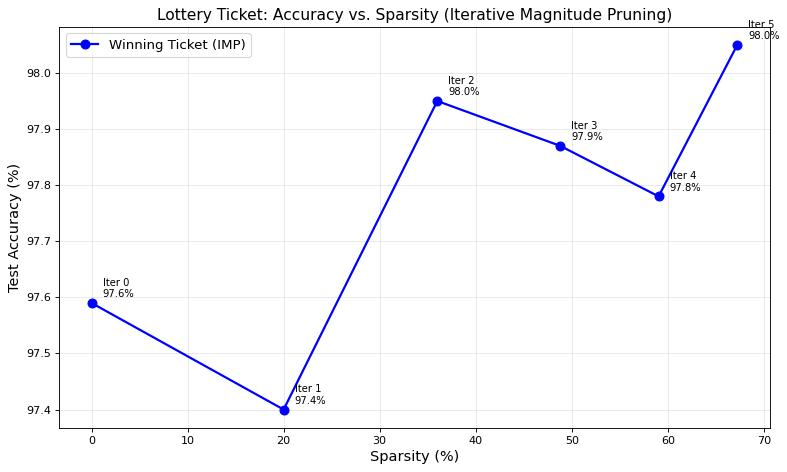

Plot saved: imp_accuracy_vs_sparsity.png


In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

# Plot final accuracy at each sparsity level
final_accs = [h['test_acc'][-1] for h in imp_histories]
ax.plot(sparsities, final_accs, 'bo-', linewidth=2, markersize=8, label='Winning Ticket (IMP)')

# Add labels for each point
for i, (sp, acc) in enumerate(zip(sparsities, final_accs)):
    ax.annotate(f'Iter {i}\n{acc:.1f}%', (sp, acc), textcoords="offset points",
                xytext=(10, 5), fontsize=9)

ax.set_xlabel('Sparsity (%)', fontsize=13)
ax.set_ylabel('Test Accuracy (%)', fontsize=13)
ax.set_title('Lottery Ticket: Accuracy vs. Sparsity (Iterative Magnitude Pruning)', fontsize=14)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('imp_accuracy_vs_sparsity.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved: imp_accuracy_vs_sparsity.png")


## 9. Winning Ticket vs. Random Re-initialization

This is the key experiment from the paper. We take the final pruned mask and compare:
- **Winning Ticket:** Reset surviving weights to their *original* initialization θ₀, retrain
- **Random Re-init:** Same mask, but surviving weights get *new* random values, retrain

The paper's hypothesis predicts that the winning ticket does better. Section 11 and the Summary report whether it did in this run.


In [9]:
def train_with_mask_and_init(mask, init_state, train_loader, test_loader, epochs=15, lr=1e-3, reinit=False):
    """Train a fresh model with the given mask, either from original init or re-initialized."""
    torch.manual_seed(SEED)
    model = SimpleMLP().to(device)

    if reinit:
        # Re-initialize with a DIFFERENT random seed
        torch.manual_seed(SEED + 999)
        model = SimpleMLP().to(device)
        # Restore original seed for data loading consistency
        torch.manual_seed(SEED + 1)
        apply_mask_to_model(model, mask)
    else:
        # Reset to original initialization
        reset_to_initial_weights(model, init_state, mask)

    print(f"Training {'Random Re-init' if reinit else 'Winning Ticket'} (sparsity: "
          f"{100.0 * sum((m==0).sum().item() for m in mask.values()) / sum(m.numel() for m in mask.values()):.1f}%)")
    history = train_model(model, mask, train_loader, test_loader, epochs=epochs, lr=lr)
    return model, history


In [10]:
# Use the mask from the last IMP iteration (most pruned)
final_mask = imp_masks[-1]
print(f"Using final mask with sparsity: {sparsities[-1]:.1f}%\n")

# Winning Ticket: original initialization + final mask
wt_model, wt_history = train_with_mask_and_init(
    final_mask, init_weights, train_loader, test_loader, epochs=15, lr=1e-3, reinit=False
)

print()

# Random Re-init: new random weights + same mask
ri_model, ri_history = train_with_mask_and_init(
    final_mask, init_weights, train_loader, test_loader, epochs=15, lr=1e-3, reinit=True
)

# Also train the full model from scratch for reference
print("\nTraining Full Model (reference)...")
torch.manual_seed(SEED)
full_model = SimpleMLP().to(device)
full_history = train_model(full_model, None, train_loader, test_loader, epochs=15, lr=1e-3)


Using final mask with sparsity: 67.2%

Training Winning Ticket (sparsity: 67.2%)


  Epoch 1/15 — Loss: 0.1880, Test Acc: 97.44%


  Epoch 2/15 — Loss: 0.0492, Test Acc: 98.04%


  Epoch 3/15 — Loss: 0.0292, Test Acc: 98.05%


  Epoch 4/15 — Loss: 0.0201, Test Acc: 98.10%


  Epoch 5/15 — Loss: 0.0160, Test Acc: 98.18%


... (36 outputs left out)

  Epoch 12/15 — Loss: 0.0150, Test Acc: 98.03%


  Epoch 13/15 — Loss: 0.0157, Test Acc: 97.73%


  Epoch 14/15 — Loss: 0.0159, Test Acc: 97.77%


  Epoch 15/15 — Loss: 0.0140, Test Acc: 97.89%


## 10. Results — Winning Ticket vs. Random Re-init vs. Full Model


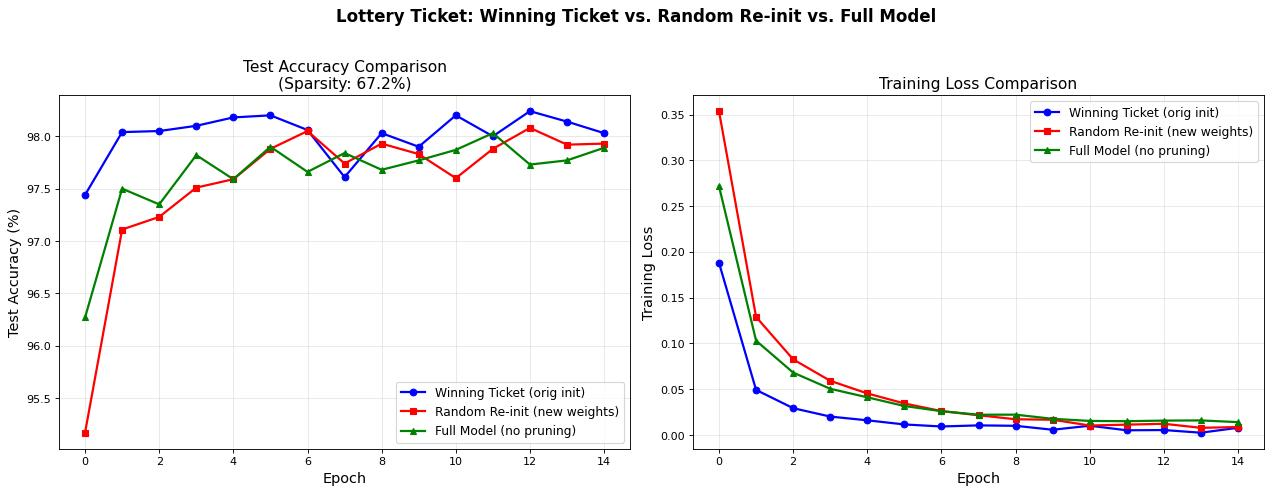

Plot saved: winning_ticket_vs_reinit.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy comparison
ax = axes[0]
ax.plot(wt_history['test_acc'], 'bo-', linewidth=2, markersize=6, label='Winning Ticket (orig init)')
ax.plot(ri_history['test_acc'], 'rs-', linewidth=2, markersize=6, label='Random Re-init (new weights)')
ax.plot(full_history['test_acc'], 'g^-', linewidth=2, markersize=6, label='Full Model (no pruning)')
ax.set_xlabel('Epoch', fontsize=13)
ax.set_ylabel('Test Accuracy (%)', fontsize=13)
ax.set_title(f'Test Accuracy Comparison\n(Sparsity: {sparsities[-1]:.1f}%)', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

# Loss comparison
ax = axes[1]
ax.plot(wt_history['train_loss'], 'bo-', linewidth=2, markersize=6, label='Winning Ticket (orig init)')
ax.plot(ri_history['train_loss'], 'rs-', linewidth=2, markersize=6, label='Random Re-init (new weights)')
ax.plot(full_history['train_loss'], 'g^-', linewidth=2, markersize=6, label='Full Model (no pruning)')
ax.set_xlabel('Epoch', fontsize=13)
ax.set_ylabel('Training Loss', fontsize=13)
ax.set_title('Training Loss Comparison', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.suptitle('Lottery Ticket: Winning Ticket vs. Random Re-init vs. Full Model',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('winning_ticket_vs_reinit.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved: winning_ticket_vs_reinit.png")


## 11. Results


In [12]:
print("=" * 70)
print("LOTTERY TICKET HYPOTHESIS — EXPERIMENT SUMMARY")
print("=" * 70)

print(f"\n1. IMP Results (Accuracy vs Sparsity):")
for i, (sp, h) in enumerate(zip(sparsities, imp_histories)):
    print(f"   Iteration {i}: Sparsity={sp:.1f}%, Final Acc={h['test_acc'][-1]:.2f}%")

print(f"\n2. Final Comparison (15 epochs each):")
print(f"   Full Model (100% weights):      {full_history['test_acc'][-1]:.2f}%")
print(f"   Winning Ticket ({sparsities[-1]:.1f}% pruned):    {wt_history['test_acc'][-1]:.2f}%")
print(f"   Random Re-init ({sparsities[-1]:.1f}% pruned):    {ri_history['test_acc'][-1]:.2f}%")

print(f"\n3. Ticket minus Random Re-init (final epoch):")
acc_gap = wt_history['test_acc'][-1] - ri_history['test_acc'][-1]
print(f"   Accuracy gap: {acc_gap:+.2f} points")
print(f"   Best-epoch accuracy, ticket: {max(wt_history['test_acc']):.2f}%")
print(f"   Best-epoch accuracy, re-init: {max(ri_history['test_acc']):.2f}%")
print("=" * 70)


LOTTERY TICKET HYPOTHESIS — EXPERIMENT SUMMARY

1. IMP Results (Accuracy vs Sparsity):
   Iteration 0: Sparsity=0.0%, Final Acc=97.59%
   Iteration 1: Sparsity=20.0%, Final Acc=97.40%
   Iteration 2: Sparsity=36.0%, Final Acc=97.95%
   Iteration 3: Sparsity=48.8%, Final Acc=97.87%
   Iteration 4: Sparsity=59.0%, Final Acc=97.78%
   Iteration 5: Sparsity=67.2%, Final Acc=98.05%

2. Final Comparison (15 epochs each):
   Full Model (100% weights):      97.89%
   Winning Ticket (67.2% pruned):    98.03%
   Random Re-init (67.2% pruned):    97.93%

3. Ticket minus Random Re-init (final epoch):
   Accuracy gap: +0.10 points
   Best-epoch accuracy, ticket: 98.24%
   Best-epoch accuracy, re-init: 98.08%


## 12. Summary

### What the run above shows

- **Pruning compounds.** After rounds 1 to 5 the sparsity is 20.0%, 36.0%, 48.8%, 59.0% and 67.2%, leaving 76,922 of 234,752 weights.
- **Accuracy held up during pruning.** The 5-epoch rounds ended between 97.40% and 98.05%, from 97.59% at 0% sparsity to 98.05% at 67.2%, with no steady trend.
- **Final accuracy at 67.2% sparsity (15 epochs):** full model **97.89%**, winning ticket **98.03%**, random re-init **97.93%**. The ticket's lead over re-init is 0.10 points (best epoch: 98.24% vs 98.08%). Accuracy moves by more than that from one epoch to the next, and this is a single seed, so this run does not show the ticket ending up more accurate.
- **Where the ticket did differ is early training.** After epoch 1 it had 97.44% test accuracy and 0.188 training loss, against 95.17% and 0.354 for re-init and 96.27% and 0.272 for the full model. It stayed ahead of re-init for the first 7 epochs; after that the two curves cross and mix.
- **Limits.** This is one seed of a small MLP, pruned only to 67.2%. In the paper (Section 2, Lenet on MNIST, averaged over trials) the gap shows at heavier pruning: with 21% of weights left, the ticket reached minimum validation loss 2.51x faster than when reinitialized and was half a percentage point more accurate.
